# Predicting Steel-Plant Energy Consumption — All 8 Experiments

**Complete lab notebook:** explanations, runnable project code, and the real dataset's generated outputs are combined here in experiment order. The target is `Usage_kWh` (15-minute regression). All dataset results below come from the supplied 35,040-row steel-industry CSV; no demo/dummy dataset is used.

> Run from the project folder. Install dependencies with `python -m pip install -r requirements.txt`. Most expensive model training is not repeated automatically: the notebook loads and reports the already-trained v6 models and saved results. To retrain explicitly, use Experiment 5's optional command.

## Contents
1. Problem definition · 2. Dataset description · 3. Preprocessing · 4. EDA · 5. Model training · 6. Evaluation · 7. Deployment · 8. Monitoring

## Shared project setup

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

# Locate this project's root whether Jupyter starts here or in its notebooks/ folder.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in _candidates if (p / "steel_energy" / "config.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the Steel_Energy_Project_Complete folder.")
sys.path.insert(0, str(PROJECT_ROOT))
DATA_PATH = PROJECT_ROOT / "Steel_industry_data 3.csv"
REPORT_DIR = PROJECT_ROOT / "outputs" / "reports"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
MODEL_DIR = PROJECT_ROOT / "artifacts" / "models"
print(f"Project: {PROJECT_ROOT}")
print(f"Dataset exists: {DATA_PATH.is_file()}")
print(f"Reports: {REPORT_DIR}")

Project: /Users/yashrathore/Desktop/Predict-energy-consumption/Steel_Energy_Project_Complete
Dataset exists: True
Reports: /Users/yashrathore/Desktop/Predict-energy-consumption/Steel_Energy_Project_Complete/outputs/reports


# Experiment 1 — Problem Definition

**Problem statement:** Forecast electricity consumption for an upcoming 15-minute interval at a steel plant so energy and production teams can plan energy use and procurement.

- **ML task:** Supervised regression evaluated chronologically as a time-series problem.
- **Target:** `Usage_kWh`.
- **Inputs:** reactive power and power-factor sensor readings, calendar/time features, known `Load_Type`, and lagged historical energy. `CO2(tCO2)` is excluded from model inputs due to unclear availability timing and high correlation (leakage risk).
- **Stakeholders:** plant energy/procurement, production planning, instrumentation and ML maintenance teams.
- **Success measures:** MAE, MSE, RMSE, MAPE (zero actuals excluded), and R²; compare to persistence baseline and choose on validation RMSE.
- **Constraints:** only one plant/year; future sensor/load values must be known or forecast separately; split chronologically; forecasts are planning aids, not safety controls.
- **Why ML:** tree regressors can learn nonlinear relationships between operating load, sensors, calendar effects, and recent energy use.

In [2]:
problem_definition = {
    "task": "15-minute-ahead supervised regression with chronological evaluation",
    "target": "Usage_kWh",
    "frequency": "15 minutes",
    "candidate_models": ["Random Forest", "XGBoost"],
    "validation_selection_metric": "RMSE (lower is better)",
    "final_metrics": ["MAE", "MSE", "RMSE", "MAPE", "R2"],
    "baseline": "Persistence: next interval equals the last measured Usage_kWh",
    "main_constraints": ["One plant and one year of source data", "Future sensor/load values required", "No random time-series split"],
}
display(pd.Series(problem_definition, name="Project definition").to_frame())

,Project definition
task,15-minute-ahead supervised regression with chr...
target,Usage_kWh
frequency,15 minutes
candidate_models,"[Random Forest, XGBoost]"
validation_selection_metric,RMSE (lower is better)
final_metrics,"[MAE, MSE, RMSE, MAPE, R2]"
baseline,Persistence: next interval equals the last mea...
main_constraints,"[One plant and one year of source data, Future..."


# Experiment 2 — Dataset Description

Dataset source: [UCI Steel Industry Energy Consumption, dataset 851](https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption), DOI 10.24432/C52G8C. The source has 15-minute readings for 2018. UCI's original published target is `Load_Type`; this project explicitly reframes the task as regression with `Usage_kWh` as the target.

In [3]:
raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
raw["date"] = pd.to_datetime(raw["date"], dayfirst=True)
print(f"Dataset shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
print("\nFirst five records")
display(raw.head())
print("\nLast five records")
display(raw.tail())
print("\nColumn types")
display(raw.dtypes.rename("dtype").to_frame())
print("\nMissing values per column")
display(raw.isna().sum().rename("missing").to_frame())
print(f"Exact duplicate rows: {raw.duplicated().sum()}")
print("\nTarget summary (Usage_kWh)")
display(raw["Usage_kWh"].describe().to_frame())
print("\nFeature dictionary: date = interval timestamp; Usage_kWh = target; reactive-power and power-factor columns = electrical measurements; NSM = seconds from midnight; WeekStatus/Day_of_week = calendar labels; Load_Type = operating category; CO2(tCO2) = source emissions field.")

Dataset shape: 35,040 rows × 11 columns

First five records


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,2018-01-01 00:15:00,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,2018-01-01 00:30:00,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,2018-01-01 00:45:00,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,2018-01-01 01:00:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,2018-01-01 01:15:00,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load



Last five records


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
35035,2018-12-31 23:00:00,3.85,4.86,0.00,0.0,62.10,100.00,82800,Weekday,Monday,Light_Load
35036,2018-12-31 23:15:00,3.74,3.74,0.00,0.0,70.71,100.00,83700,Weekday,Monday,Light_Load
35037,2018-12-31 23:30:00,3.78,3.17,0.07,0.0,76.62,99.98,84600,Weekday,Monday,Light_Load
35038,2018-12-31 23:45:00,3.78,3.06,0.11,0.0,77.72,99.96,85500,Weekday,Monday,Light_Load
35039,2018-12-31 00:00:00,3.67,3.02,0.07,0.0,77.22,99.98,0,Weekday,Monday,Light_Load



Column types


...


Missing values per column


,missing
date,0
Usage_kWh,0
Lagging_Current_Reactive.Power_kVarh,0
Leading_Current_Reactive_Power_kVarh,0
CO2(tCO2),0
Lagging_Current_Power_Factor,0
Leading_Current_Power_Factor,0
NSM,0
WeekStatus,0
Day_of_week,0


Exact duplicate rows: 0

Target summary (Usage_kWh)


,Usage_kWh
count,35040.000000
mean,27.386892
std,33.444380
min,0.000000
25%,3.200000
50%,4.570000
75%,51.237500
max,157.180000



Feature dictionary: date = interval timestamp; Usage_kWh = target; reactive-power and power-factor columns = electrical measurements; NSM = seconds from midnight; WeekStatus/Day_of_week = calendar labels; Load_Type = operating category; CO2(tCO2) = source emissions field.


# Experiment 3 — Data Preprocessing and Feature Engineering

The project parser normalizes timestamps, removes exact duplicates, orders observations, builds the complete 15-minute time grid, adds calendar and shifted historical lag/rolling features, and creates a 70%/15%/15% chronological split. Imputers/encoders are fit inside model pipelines on training folds, avoiding validation/test leakage. Missing target readings are not fabricated; the first 96 intervals are excluded from model-ready splits because they lack full lag history.

In [4]:
from steel_energy.preprocessing import run_preprocessing

preprocessing_summary = run_preprocessing(
    source_path=DATA_PATH,
    output_dir=PROJECT_ROOT / "data" / "processed",
    report_dir=REPORT_DIR,
)
summary_view = {
    key: preprocessing_summary[key]
    for key in ["input_rows", "exact_duplicates_removed", "missing_intervals_inserted",
                "rows_with_missing_target", "cleaned_rows", "usable_rows",
                "train_rows", "validation_rows", "test_rows", "target",
                "first_timestamp", "last_timestamp"]
}
display(pd.Series(summary_view, name="Preprocessing result").to_frame())
engineered = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "engineered_features.csv")
print("Engineered feature preview")
display(engineered.head())

,Preprocessing result
input_rows,35040
exact_duplicates_removed,0
missing_intervals_inserted,0
rows_with_missing_target,0
cleaned_rows,35040
usable_rows,34944
train_rows,24460
validation_rows,5242
test_rows,5242
target,Usage_kWh


Engineered feature preview


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,hour,day,day_of_week_num,...,is_weekend,lag_1,lag_4,lag_96,rolling_mean_4,rolling_std_4,rolling_mean_96,WeekStatus,Day_of_week,Load_Type
0,2018-01-01 00:00:00,3.42,3.46,0.0,70.30,100.0,0,0,1,0,...,0,NaN,NaN,NaN,NaN,NaN,NaN,Weekday,Monday,Light_Load
1,2018-01-01 00:15:00,3.17,2.95,0.0,73.21,100.0,900,0,1,0,...,0,3.42,NaN,NaN,NaN,NaN,NaN,Weekday,Monday,Light_Load
2,2018-01-01 00:30:00,4.00,4.46,0.0,66.77,100.0,1800,0,1,0,...,0,3.17,NaN,NaN,NaN,NaN,NaN,Weekday,Monday,Light_Load
3,2018-01-01 00:45:00,3.24,3.28,0.0,70.28,100.0,2700,0,1,0,...,0,4.00,NaN,NaN,NaN,NaN,NaN,Weekday,Monday,Light_Load
4,2018-01-01 01:00:00,3.31,3.56,0.0,68.09,100.0,3600,1,1,0,...,0,3.24,3.42,NaN,3.4575,0.376685,NaN,Weekday,Monday,Light_Load


# Experiment 4 — Exploratory Data Analysis (EDA)

EDA checks time trends, weekday/weekend and load patterns, the target distribution, power-factor relationships, numeric correlations, autocorrelation, and outliers. The generated plots and insight report are produced by the same `steel_energy.eda` code used by the standalone project.

Key EDA insights from the real dataset:
1. Usage_kWh has skewness 1.20; the distribution is right-skewed relative to a symmetric distribution.
2. Mean usage is 27.39 kWh per interval and median is 4.57 kWh, indicating that the median is a useful robust reference.
3. Weekend mean usage is 11.73 kWh and weekday mean usage is 33.62 kWh.
4. Maximum_Load has the highest average usage (59.27 kWh per interval) among the recorded load types.
5. Monthly average usage is highest in January (42.42 kWh) and lowest in December (19.97 kWh); one year cannot establish a recurring annual season.
6. `CO2(tCO2)` has the largest absolute Pearson correlation with Usage_kWh among the numeric source features (r=0.988).
7. Autocorrelation is 0.912 at 15 minutes and 0.606 at 24 hours, supporting chronological lag features.
8. About 0.9% of target readings lie outside the 1.5-IQR whiskers; inspect these operating peaks rather than deleting them automatically.
consumption_timeseries.png


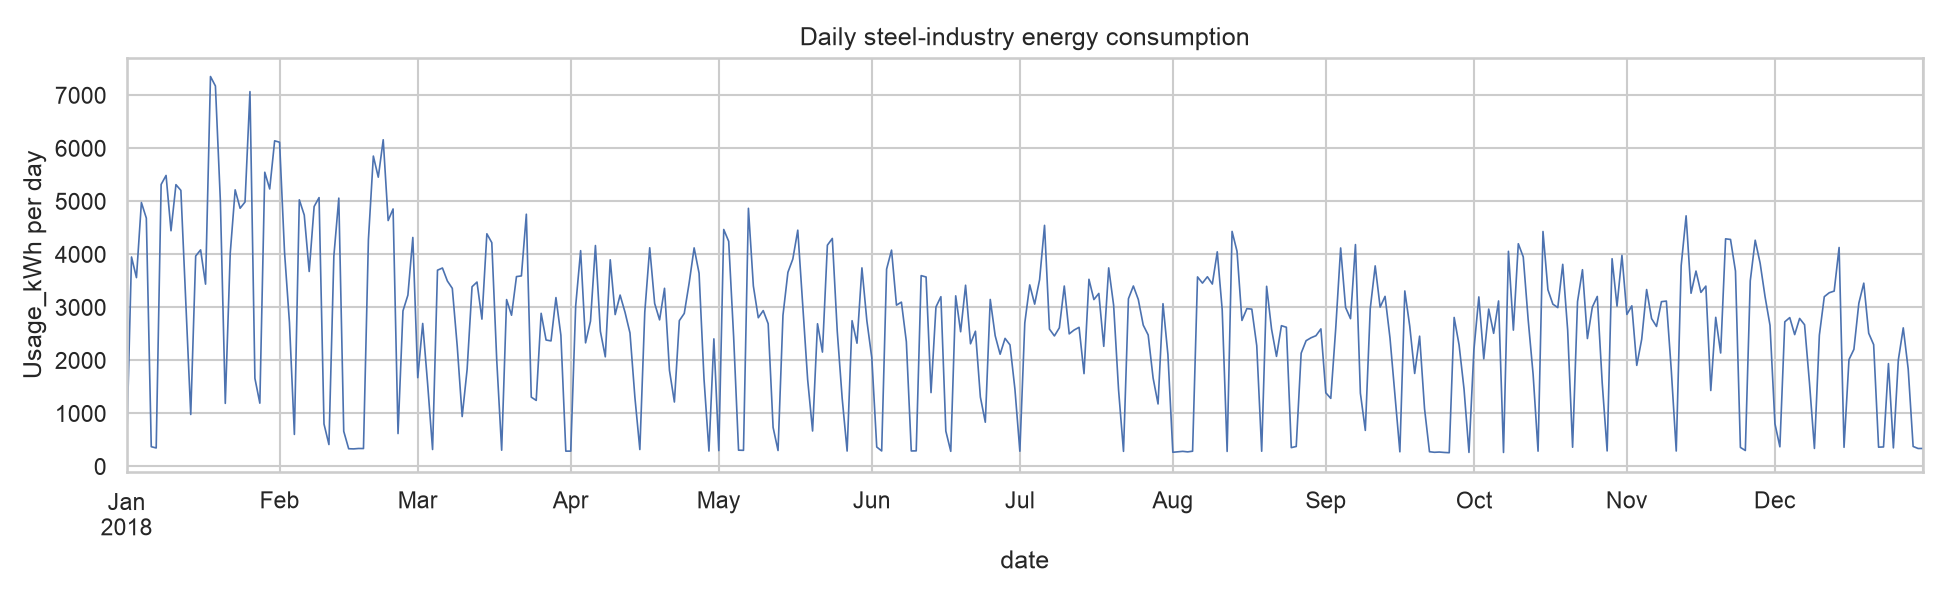

daily_weekly_patterns.png


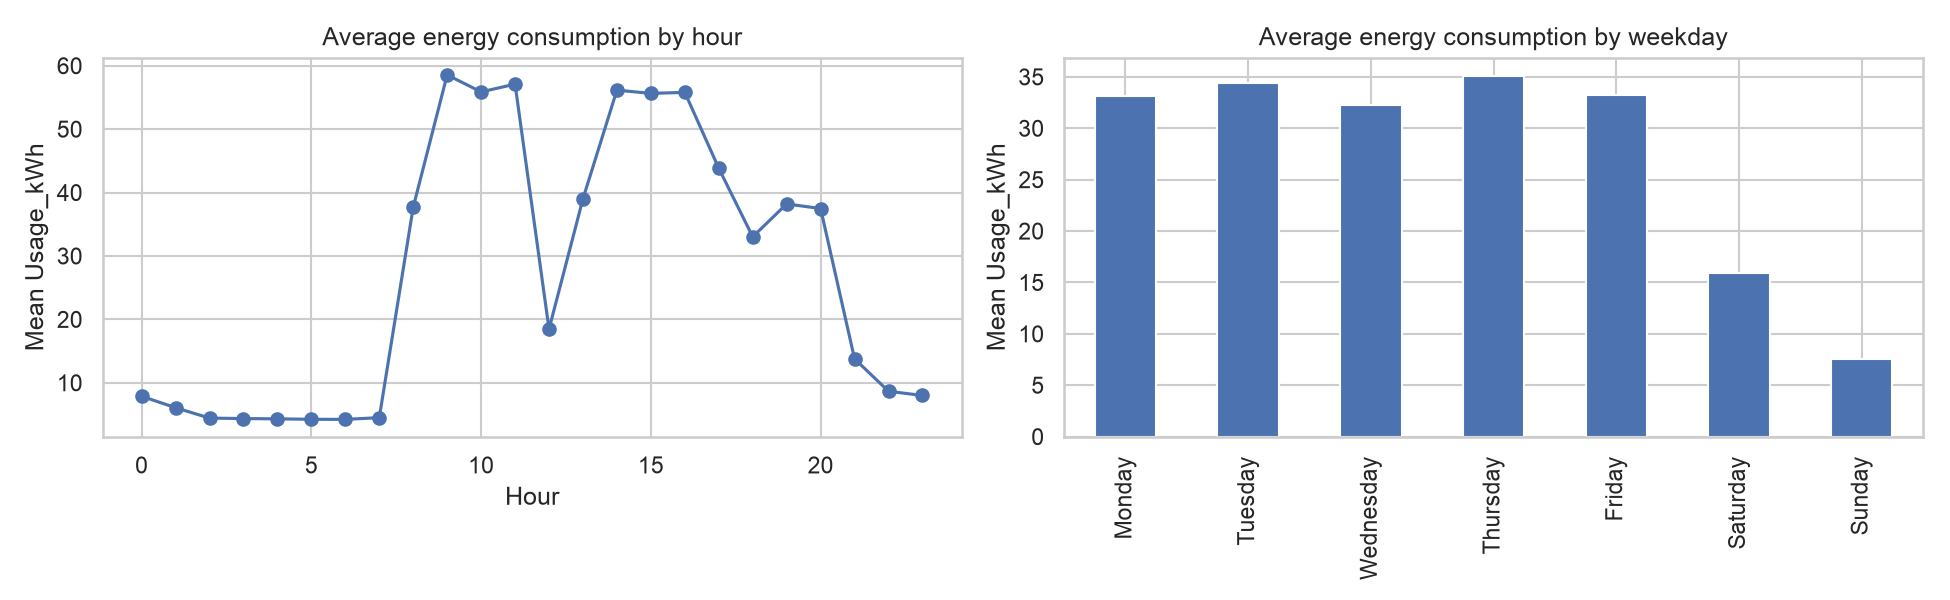

target_distribution.png


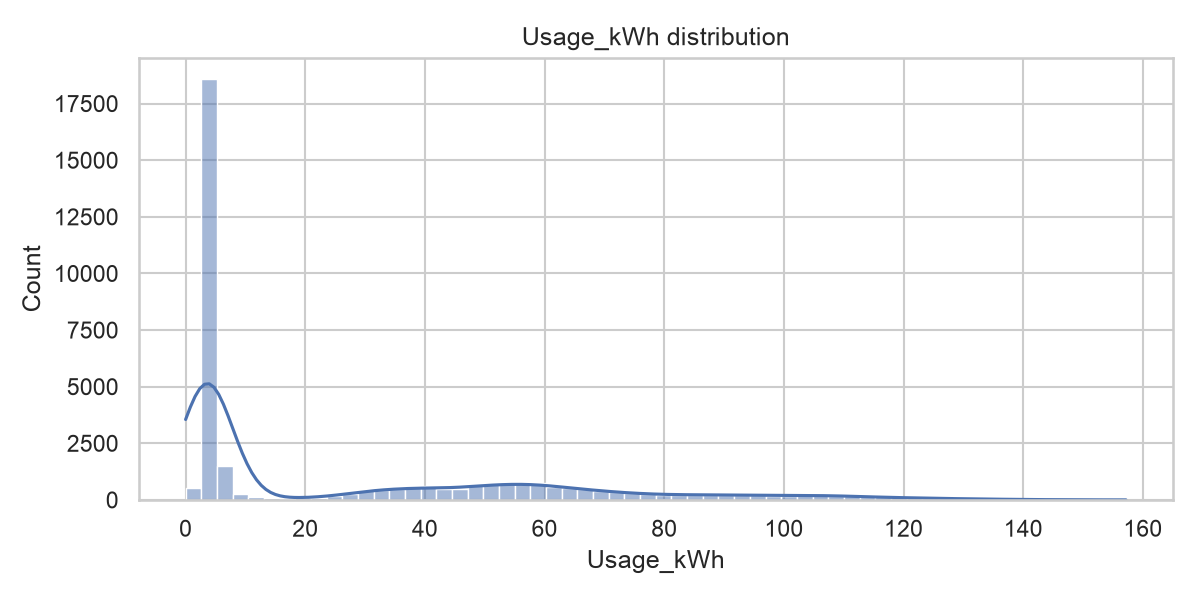

load_type_comparison.png


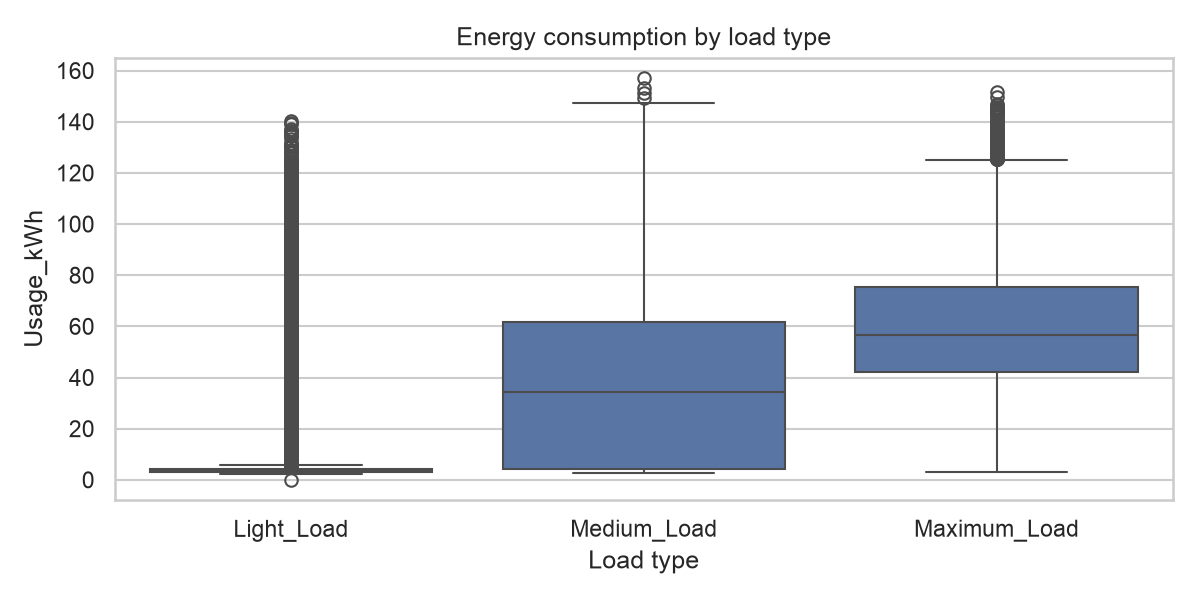

power_factor_relationships.png


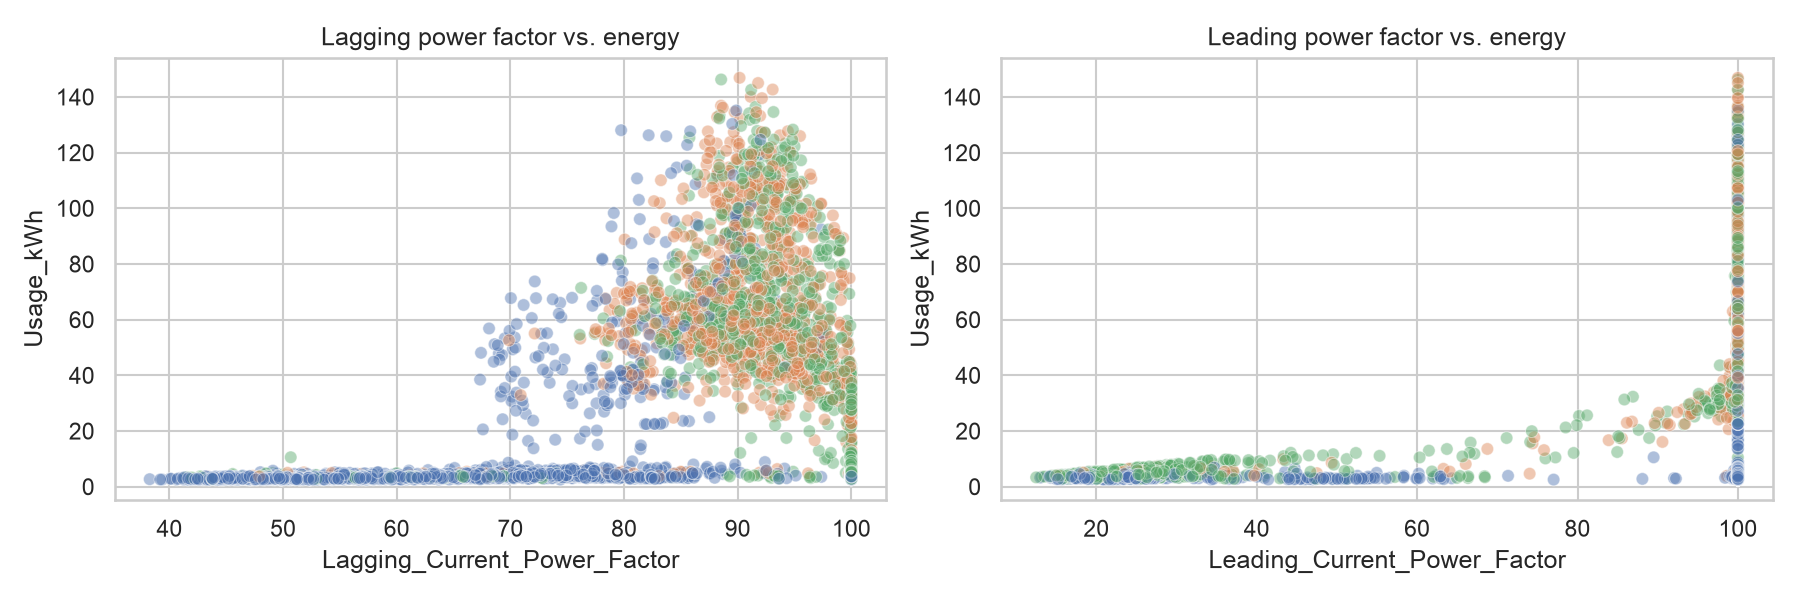

correlation_heatmap.png


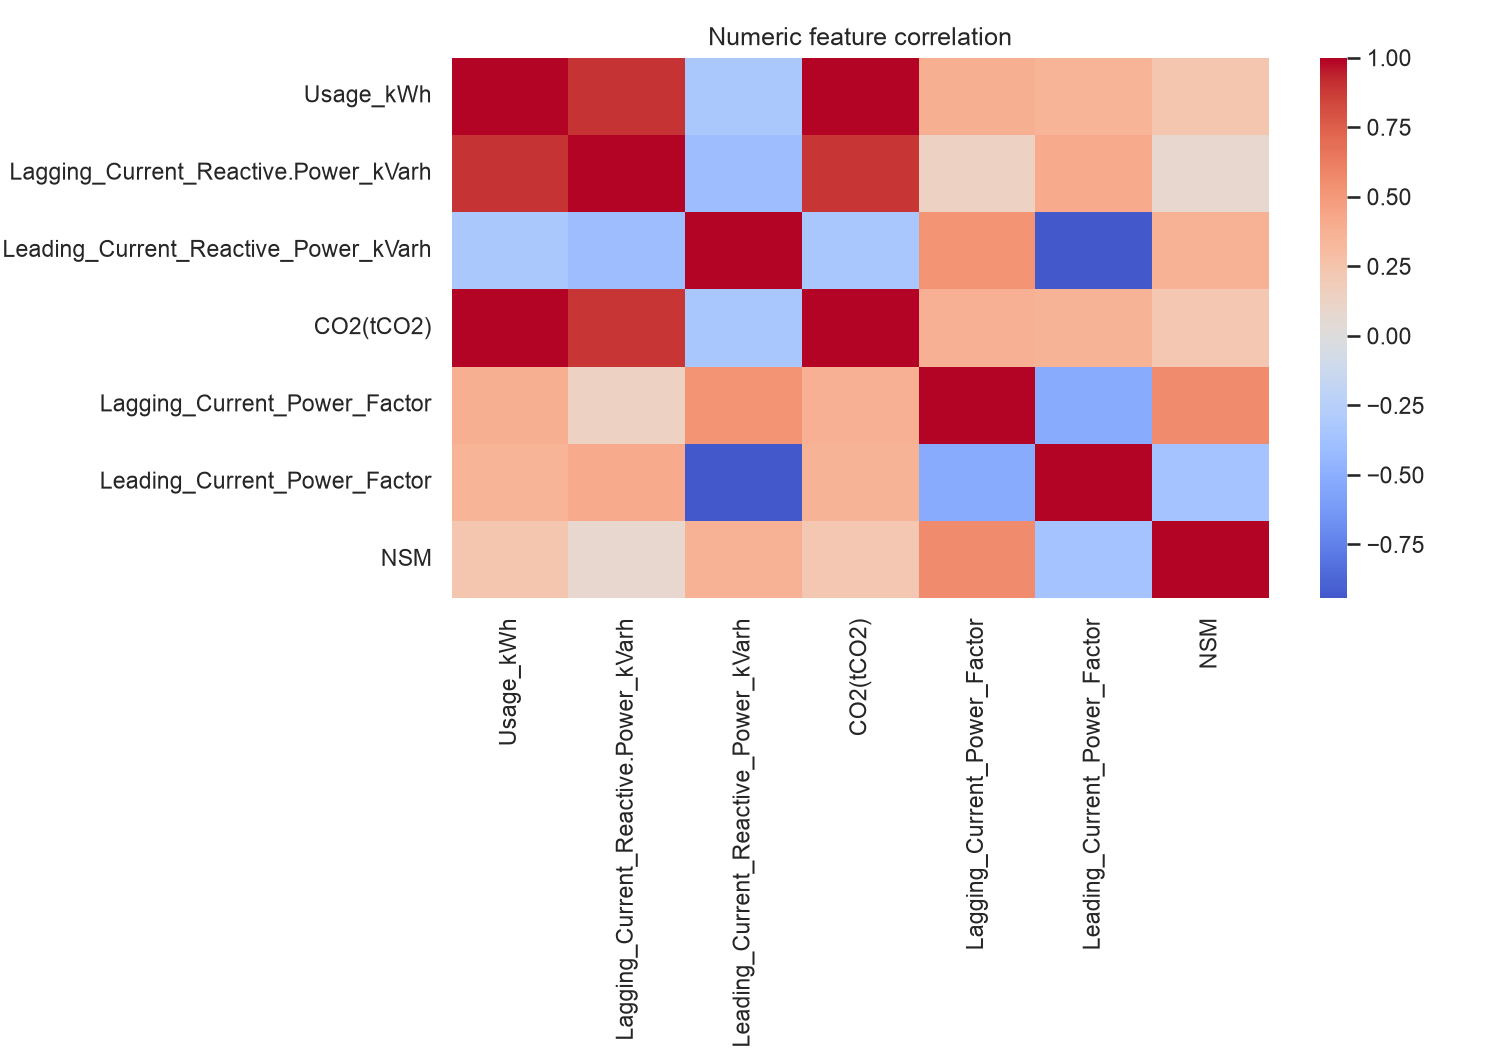

autocorrelation.png


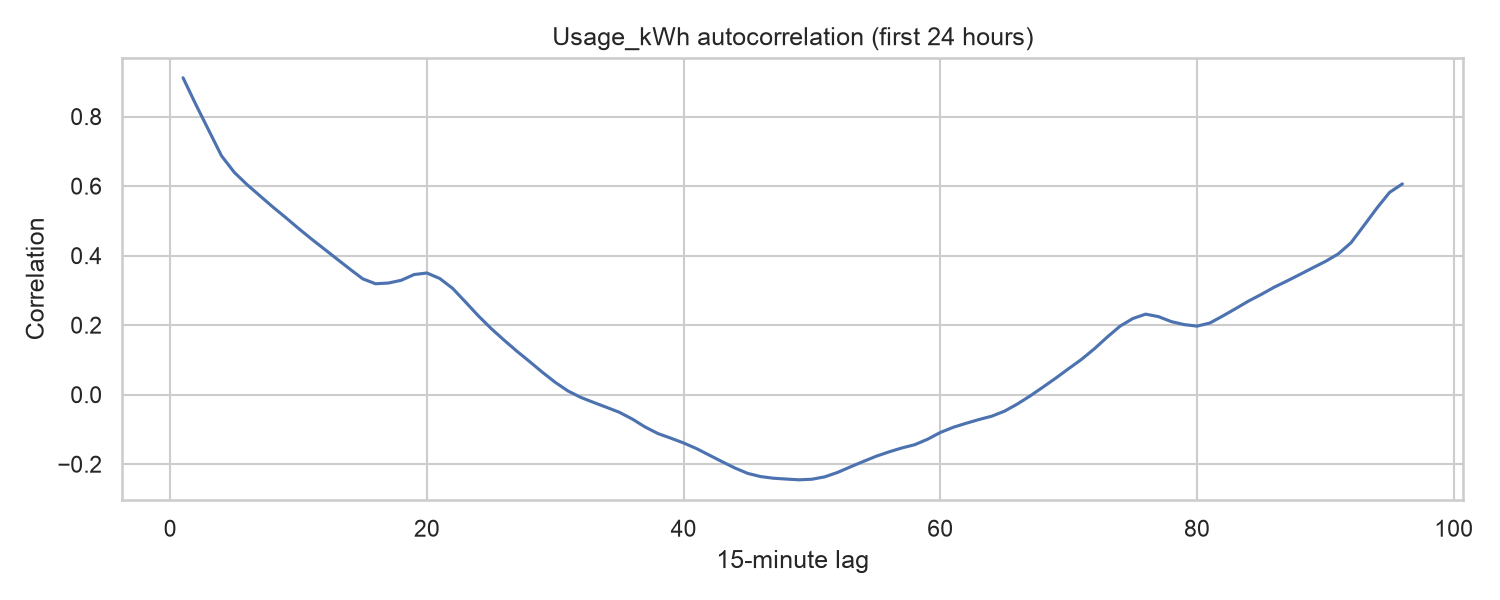

In [5]:
from steel_energy.eda import run_eda

eda_report = run_eda(data_path=DATA_PATH)
print("Key EDA insights from the real dataset:")
for number, insight in enumerate(eda_report["insights"], start=1):
    print(f"{number}. {insight}")
figure_names = ["consumption_timeseries.png", "daily_weekly_patterns.png",
                "target_distribution.png", "load_type_comparison.png",
                "power_factor_relationships.png", "correlation_heatmap.png",
                "autocorrelation.png"]
for figure_name in figure_names:
    path = FIGURE_DIR / figure_name
    print(figure_name)
    display(Image(filename=str(path)))

**How EDA guides modeling:** preserve chronology; include calendar and lag features; compare with persistence; retain genuine operating peaks; do not use `CO2(tCO2)` as a predictor until its timing is proven; monitor errors by load type.

# Experiment 5 — Model Implementation and Training

The training script tunes Random Forest and XGBoost using `GridSearchCV` with `TimeSeriesSplit` on the training partition. Validation RMSE selects the model; the held-out test period is not used for selection. A persistence baseline is included. This notebook shows the actual saved v6 training result and model parameters to avoid an unnecessary multi-minute retrain on each notebook run.

To train a new version deliberately, uncomment and run: `from steel_energy.modeling import train_models; training_result = train_models()` (it will generate/activate new model artifacts).

In [6]:
training_report = json.loads((REPORT_DIR / "training_report.json").read_text())
manifest = json.loads((MODEL_DIR / "active_model.json").read_text())
print(f"Active model: {manifest['model_name']} ({manifest['model_version']})")
print(f"Selection criterion: {manifest['selection_metric']}")
print(f"Validation RMSE: {manifest['validation_rmse']:.3f} kWh")
print("\nTuned parameters and validation scores")
model_rows = []
for name, details in training_report["models"].items():
    model_rows.append({"model": name, "best_params": details["best_params"],
                       "CV RMSE": details["best_cv_rmse"],
                       "validation RMSE": details["validation_metrics"]["RMSE"]})
display(pd.DataFrame(model_rows).set_index("model"))
validation_comparison = pd.read_csv(REPORT_DIR / "model_comparison_validation.csv")
display(validation_comparison)

Active model: random_forest (v6)
Selection criterion: validation RMSE (lower is better)
Validation RMSE: 1.303 kWh

Tuned parameters and validation scores


,best_params,CV RMSE,validation RMSE
model,,,
random_forest,"{'regressor__max_leaf_nodes': 512, 'regressor_...",2.526420,1.302976
xgboost,"{'regressor__learning_rate': 0.05, 'regressor_...",2.123195,1.396288


,model,MAE,MSE,RMSE,MAPE_percent_nonzero_actuals,R2,rows,zero_actual_rows_excluded_from_MAPE
0,random_forest,0.624973,1.697746,1.302976,7.653958,0.998181,5242,1
1,xgboost,0.747709,1.949621,1.396288,6.819970,0.997911,5242,1
2,persistence_baseline,5.725340,162.617681,12.752164,24.275725,0.825765,5242,1


# Experiment 6 — Model Evaluation

The model is evaluated on the future held-out test period with MAE, MSE, RMSE, MAPE, and R². MAPE excludes zero-usage rows. Actual-vs-predicted and residual plots show fit and error behavior. The final model was selected by validation RMSE; XGBoost happens to score better on this single held-out test segment, which is not used to retrospectively change that selection.

Held-out test period: 2018-11-07 09:30:00 to 2018-12-31 23:45:00
Evaluation scope: Rolling one-step forecasts: each row's lag features use previously measured Usage_kWh, including within the test period. Recursive multi-step performance is not represented by these metrics.


,MAE,MSE,RMSE,MAPE_percent_nonzero_actuals,R2,rows
model,,,,,,
persistence_baseline,5.0557,135.8322,11.6547,20.1051,0.8603,5242
random_forest,1.0310,5.6463,2.3762,8.0594,0.9942,5242
xgboost,0.9659,3.1839,1.7844,7.4989,0.9967,5242



Actual vs predicted


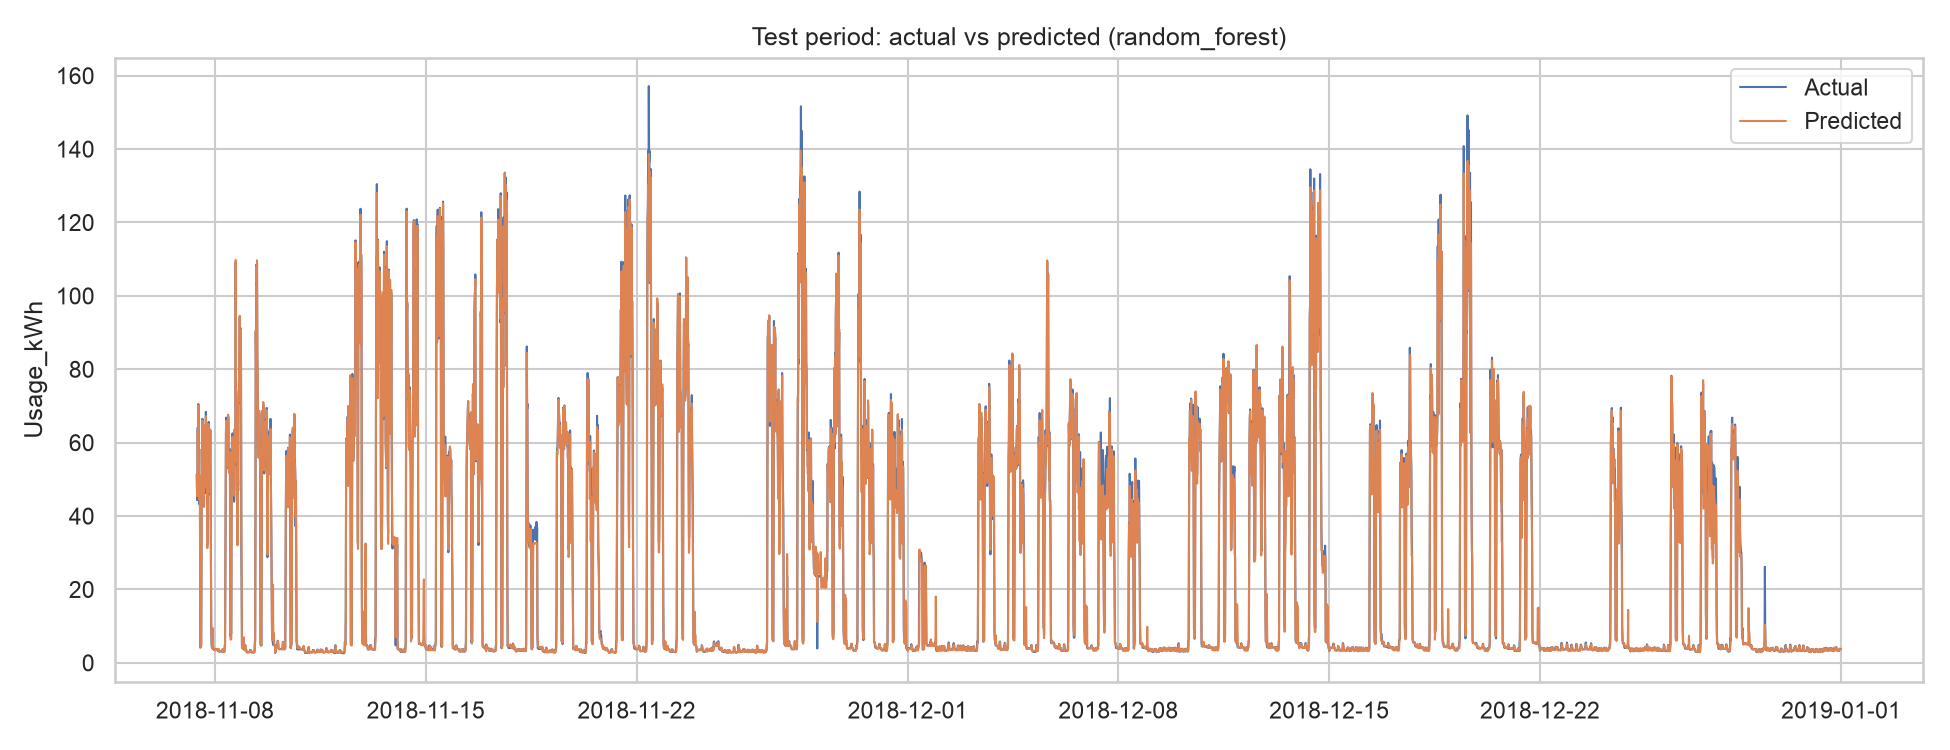

Residual analysis (residual = actual - predicted)


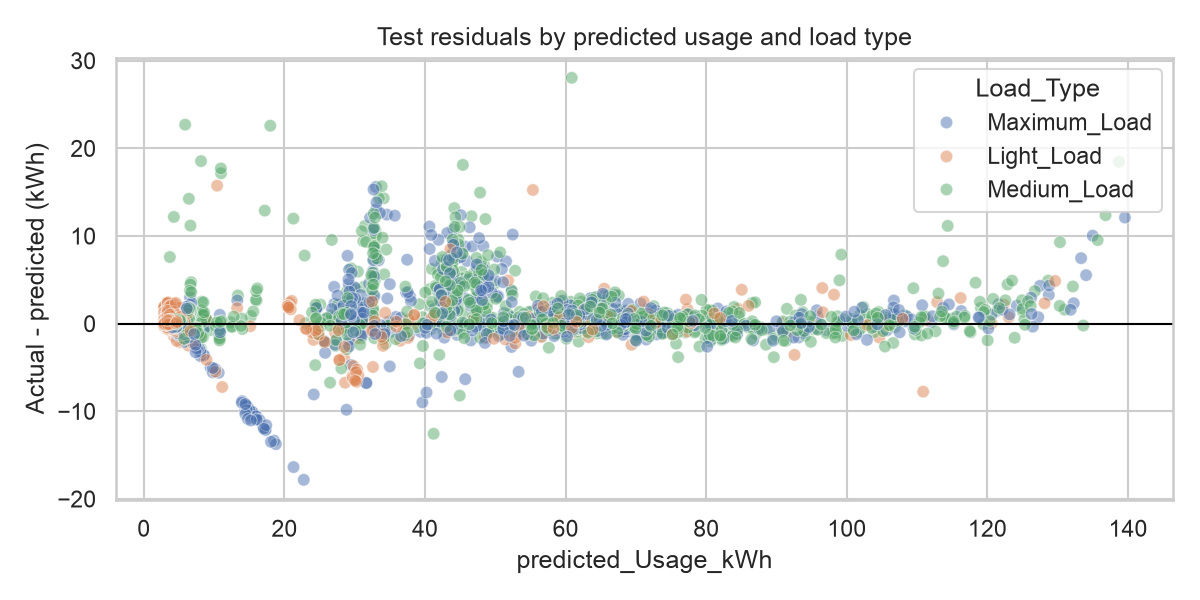


Worst observed test errors


,date,actual_Usage_kWh,predicted_Usage_kWh,error_kWh,absolute_error_kWh,Load_Type
0,2018-12-13 16:15:00,88.92,60.866635,28.053365,28.053365,Medium_Load
1,2018-12-01 09:15:00,28.58,5.872024,22.707976,22.707976,Medium_Load
2,2018-12-27 13:15:00,40.57,17.984228,22.585772,22.585772,Medium_Load
3,2018-12-05 13:00:00,26.68,8.133763,18.546237,18.546237,Medium_Load
4,2018-11-22 09:45:00,157.18,138.702236,18.477764,18.477764,Medium_Load
5,2018-12-13 15:45:00,63.50,45.378735,18.121265,18.121265,Medium_Load
6,2018-11-14 22:30:00,4.93,22.744308,-17.814308,17.814308,Maximum_Load
7,2018-11-10 13:15:00,28.66,10.951940,17.708060,17.708060,Medium_Load
8,2018-11-20 13:15:00,28.15,10.989013,17.160987,17.160987,Medium_Load
9,2018-11-09 22:15:00,4.93,21.294990,-16.364990,16.364990,Maximum_Load


In [7]:
evaluation = json.loads((REPORT_DIR / "model_evaluation.json").read_text())
print("Held-out test period:", evaluation["test_period"]["start"], "to", evaluation["test_period"]["end"])
print("Evaluation scope:", evaluation["evaluation_scope"])
metrics = pd.DataFrame(evaluation["test_metrics"]).set_index("model")
display(metrics[["MAE", "MSE", "RMSE", "MAPE_percent_nonzero_actuals", "R2", "rows"]].round(4))
print("\nActual vs predicted")
display(Image(filename=str(FIGURE_DIR / "actual_vs_predicted.png")))
print("Residual analysis (residual = actual - predicted)")
display(Image(filename=str(FIGURE_DIR / "residuals.png")))
print("\nWorst observed test errors")
worst_errors = pd.read_csv(REPORT_DIR / "error_analysis_worst_25.csv")
display(worst_errors.head(10))

# Experiment 7 — Deployment with FastAPI

The FastAPI application serves a browser frontend, API prediction endpoints, and Swagger documentation. For a live one-step prediction it needs 96 consecutive measured history points plus known/estimated sensor readings and load type for the future interval. The example below uses the real dataset's last 96 readings and repeats its last sensor values as an explicitly stated demonstration assumption; it forecasts the next interval after the historical source ends, not current-day plant consumption.

Run the service locally with `uvicorn app.main:app --reload`; open `http://127.0.0.1:8000/` or `http://127.0.0.1:8000/docs`.

In [8]:
from datetime import timedelta
from urllib.request import Request, urlopen
from urllib.error import URLError

api_base = "http://127.0.0.1:8000"
health_request = Request(f"{api_base}/health")
try:
    with urlopen(health_request, timeout=5) as response:
        health = json.loads(response.read())
    print("API health:", health)

    history_rows = raw.sort_values("date").tail(96)
    history = [{"timestamp": row.date.isoformat(), "usage_kwh": float(row.Usage_kWh)}
               for row in history_rows.itertuples(index=False)]
    last_row = history_rows.iloc[-1]
    next_time = last_row["date"] + timedelta(minutes=15)
    # Demonstration assumption only: repeat the last observed sensor/load values.
    future_interval = {
        "timestamp": next_time.isoformat(),
        "Lagging_Current_Reactive.Power_kVarh": float(last_row["Lagging_Current_Reactive.Power_kVarh"]),
        "Leading_Current_Reactive_Power_kVarh": float(last_row["Leading_Current_Reactive_Power_kVarh"]),
        "Lagging_Current_Power_Factor": float(last_row["Lagging_Current_Power_Factor"]),
        "Leading_Current_Power_Factor": float(last_row["Leading_Current_Power_Factor"]),
        "Load_Type": str(last_row["Load_Type"]),
    }
    payload = {"history": history, "future_intervals": [future_interval]}
    request = Request(f"{api_base}/predict", data=json.dumps(payload).encode(),
                      headers={"Content-Type": "application/json"}, method="POST")
    with urlopen(request, timeout=30) as response:
        prediction = json.loads(response.read())
    print("Sample forecast response:")
    display(prediction)
except URLError as error:
    print(f"API is not running ({error}). Start it with: uvicorn app.main:app --reload")

API health: {'status': 'ok', 'model_ready': True, 'model_version': 'v6', 'model_name': 'random_forest'}
Sample forecast response:


{'model_version': 'v6',
 'target': 'Usage_kWh',
 'frequency': '15 minutes',
 'predictions': [{'timestamp': '2019-01-01T00:00:00',
   'predicted_Usage_kWh': 3.691963214990985}]}

# Experiment 8 — Continuous Monitoring and Maintenance

Every prediction is logged with model version and features. Monthly monitoring compares predictions to measured actuals, checks error metrics, and tests input drift with population stability index (PSI). The starter policy requires review above PSI 0.20; the performance script requests evaluation when RMSE exceeds 1.25× validation RMSE or non-zero MAPE exceeds 20%, given at least 100 matched readings. Reassess after equipment, production mix, or sensor changes; retain versioned models to support rollback.

In [9]:
monitoring = json.loads((REPORT_DIR / "monitoring_holdout_replay.json").read_text())
drift = monitoring["drift"]
performance = monitoring["performance"]
print(f"Holdout monitoring replay: {monitoring['prediction_log_records']:,} records")
print(f"Drift status: {drift['status']} (PSI threshold {drift['threshold']}; minimum rows {drift['minimum_current_rows']})")
print("Features over drift threshold:", ", ".join(drift["drifted_features"]))
print("Performance metrics:")
display(pd.Series(performance["metrics"]).to_frame("value"))
print("Evaluation required:", performance["evaluation_required"])
print("Triggers:", performance["triggers"])
print("\nTo run monitoring against new production logs and measured actuals:")
print("python -m steel_energy.monitoring --predictions outputs/logs/predictions.jsonl --actuals path/to/measured_actuals.csv")

Holdout monitoring replay: 5,242 records
Drift status: evaluated (PSI threshold 0.2; minimum rows 100)
Features over drift threshold: Lagging_Current_Reactive.Power_kVarh, Lagging_Current_Power_Factor, day_of_year, month, lag_1, lag_4, lag_96, rolling_mean_4, rolling_mean_96
Performance metrics:


,value
MAE,1.030955
MSE,5.646298
RMSE,2.376194
MAPE_percent_nonzero_actuals,8.059351
R2,0.994194
rows,5242.000000
zero_actual_rows_excluded_from_MAPE,0.000000


Evaluation required: True
Triggers: ['RMSE exceeds 1.25 times validation RMSE']

To run monitoring against new production logs and measured actuals:
python -m steel_energy.monitoring --predictions outputs/logs/predictions.jsonl --actuals path/to/measured_actuals.csv


## Conclusion

All eight lab experiments are documented in this notebook and backed by the included real CSV, preprocessing/training/evaluation code, saved v6 model artifacts, reports, and plots. The API example is conditional on future sensor inputs being available; the 2018 dataset alone does not provide current plant data. For operational use, collect current readings and have plant stakeholders approve the acceptable error thresholds.